# 24 · Análisis exploratorio: el segundo paquete de columnas y el locro estructural

**Etapa 30 del plan.** Toda la ganancia firme del trabajo vino de columnas nuevas: la historia curada, los cuatro bloques y el paquete del `22`. Los hiperparámetros (`07`, `19`, `23`), los árboles (`16`) y el *undersampling* (`18`) no sumaron. Este notebook prueba, en el banco temporal del `15`, dos cosas:

**1. El segundo paquete (`PAQ2_P3`):** `PAQ_P3` (la vigente) más cinco ingredientes que nunca se midieron en el banco temporal. Por la regla de los empates, van juntos.

| Ingrediente | Qué es | Columnas |
|---|---|---:|
| `PH` | Historial del puntaje: el percentil del puntaje de un modelo `AC` en t−1, t−2 y t−3, y la diferencia entre t−1 y t−3. El puntaje de cada mes sale de un modelo entrenado hasta dos meses antes, como en producción | 4 |
| `RF` | Hojas de Random Forest (receta de la cátedra: 20 árboles, 16 hojas, 1.000 filas por hoja, `mtry` 0,2), entrenado en cada mes evaluado con su ventana | hasta 320 |
| `RK` | Rankings con cero fijo de Tomás: percentil por mes y por signo de los 73 montos, con su lag y su delta de 1 y 2 meses | 365 |
| `MVX` | Cruce del paquete: cambios relativos y las 4 medidas de la historia curada sobre las 43 combinaciones de Visa y Master | 258 |
| `AG` | Sueldo sin aguinaldo: `mpayroll` de 201906 dividido por el cociente de su mediana contra la de 201905, con su historia | 11 |

**Decide** `PAQ2_P3` − `PAQ_P3`, en 201906–10 con 5 semillas, con la regla de acumulación: Suma si la diferencia es mayor que 0 y gana en 3 de 5 semillas.

**2. El locro estructural:** las 5 mejores combinaciones de hiperparámetros del `23` (pruebas 48, 40, 51, 55 y 58), con las columnas de `PAQ_P3`. Para cada semilla, el promedio de los puestos de las 5 (5 modelos) contra el semillerío de `PAQ_P3` (5 modelos). **Decide** en 201909–10, que no se usaron para elegirlas, con la misma regla.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/23/` ni en los `resultados/03_*` a `23_*`:** solo los lee.

Ficha: `fichas/etapa_30_segundo_paquete.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los puntajes, los bosques y los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee: control del puntaje
EXP_22 = Path('../exp/22')                          # solo se lee: la vigente
EXP_23 = Path('../exp/23')                          # solo se lee: las 5 mejores combinaciones
EXP = Path('../exp/24')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'PAQ_P3'                               # la vigente del 22: sus predicciones se leen de exp/22
PAQUETE2 = 'PAQ2_P3'                                # PAQ_P3 + PH + RF + RK + MVX + AG
LOCRO = 'LOCRO_23'                                  # las 5 mejores del 23, una semilla cada una
SEMILLERIO = 'SEMILLERIO_PAQ_P3'                    # PAQ_P3 con las 5 semillas
PESO_B2 = 3                                         # el de la vigente
LAGS_MV = [1, 2]                                    # como el 17
ROTO_NUEVO = ('Visa_mfinanciacion_limite', 201904)  # como el 17: solo en las combinaciones
LAGS_R = [1, 2]                                     # como el 20
MESES_PUNTAJE = [201905, 201906, 201907, 201908, 201909]   # meses con puntaje: cada modelo entrena hasta dos meses antes
LAGS_PUNTAJE = [1, 2, 3]
RF = {'arboles': 20, 'hojas': 16, 'datos_por_hoja': 1_000, 'mtry': 0.2}   # los del workflow de la cátedra, como el 09
PREFIJOS_RK = ('m', 'Visa_m', 'Master_m')           # como exp_rankings_cero_fijo.py de Tomás
LAGS_RK = [1, 2]
MES_AGUINALDO, MES_ANTES_AGUINALDO = 201906, 201905
PRUEBAS_LOCRO = [48, 40, 51, 55, 58]                # las 5 mejores del 23
ESTUDIO_23 = '23_paq_p3_ganancia'
MESES_LOCRO = [201909, 201910]                      # no se usaron para elegirlas
SEMILLAS_MINIMAS = 3                                # regla de acumulación: d > 0 y al menos 3 de 5 semillas a favor
FORZAR_REFERENCIA_LOCAL = False                     # True: entrena la vigente en esta máquina aunque reproduzca el 22
HIPOTESIS = {PAQUETE2: 'El segundo paquete (historial del puntaje, hojas de RF, rankings con cero fijo, cruce de Visa y Master, sueldo sin aguinaldo) gana más que PAQ_P3',
             LOCRO: 'El promedio de las 5 mejores combinaciones de hiperparámetros del 23 gana más que el semillerío de PAQ_P3 con la misma cantidad de modelos'}
ENVIOS = [2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000]   # curva por cantidad de envíos, solo para informar
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180, 'MV': 43, 'MVH': 215, 'R': 258}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123456789]_*'), *RESULTADOS.glob('2[0123]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 73


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Dataset cargado en 3 s


## 3. Tablas de `ACH_4`

Las mismas 1.180 columnas del `15` y el `22`. **Control 4:** sin fuga. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 32 s · memoria máxima 9.5 GB


## 4. Combinaciones de Visa y Master, con su historia

El mismo código del `17` y el `22` (215 columnas). **Control 4** y **control 6**, como en el `17`.

In [4]:
SUMAS = ['mfinanciacion_limite', 'msaldototal', 'msaldopesos', 'msaldodolares', 'mconsumospesos', 'mconsumosdolares',
         'mlimitecompra', 'madelantopesos', 'madelantodolares', 'mpagado', 'mpagospesos', 'mpagosdolares',
         'mconsumototal', 'cconsumos', 'cadelantosefectivo', 'mpagominimo']
MINIMOS = ['Fvencimiento', 'Finiciomora']
MAXIMOS = ['fultimo_cierre', 'fechaalta']
COCIENTES = [('mvr_Master_mlimitecompra', 'Master_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_Visa_mlimitecompra', 'Visa_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_msaldototal', 'mv_msaldototal', 'mv_mlimitecompra'),
             ('mvr_msaldopesos', 'mv_msaldopesos', 'mv_mlimitecompra'),
             ('mvr_msaldopesos2', 'mv_msaldopesos', 'mv_msaldototal'),
             ('mvr_msaldodolares', 'mv_msaldodolares', 'mv_mlimitecompra'),
             ('mvr_msaldodolares2', 'mv_msaldodolares', 'mv_msaldototal'),
             ('mvr_mconsumospesos', 'mv_mconsumospesos', 'mv_mlimitecompra'),
             ('mvr_mconsumosdolares', 'mv_mconsumosdolares', 'mv_mlimitecompra'),
             ('mvr_madelantopesos', 'mv_madelantopesos', 'mv_mlimitecompra'),
             ('mvr_madelantodolares', 'mv_madelantodolares', 'mv_mlimitecompra'),
             ('mvr_mpagado', 'mv_mpagado', 'mv_mlimitecompra'),
             ('mvr_mpagospesos', 'mv_mpagospesos', 'mv_mlimitecompra'),
             ('mvr_mpagosdolares', 'mv_mpagosdolares', 'mv_mlimitecompra'),
             ('mvr_mconsumototal', 'mv_mconsumototal', 'mv_mlimitecompra'),
             ('mvr_mpagominimo', 'mv_mpagominimo', 'mv_mlimitecompra')]
ROTOS_MV = {(v, int(m)) for v, m in rotos.itertuples(index=False)} | {ROTO_NUEVO}
assert all(f'{t}_{c}' in VARIABLES for t in ('Master', 'Visa') for c in SUMAS + MINIMOS + MAXIMOS)


def combinaciones(X, foto_mes):
    """Las 43 combinaciones del mes, fila por fila. Solo usan la foto de esa fila."""
    col = lambda v: X[:, VARIABLES.index(v)].astype(np.float64)
    roto = lambda v: np.isin(foto_mes, [m for w, m in ROTOS_MV if w == v])
    s = {}
    ms, vs = col('Master_status'), col('Visa_status')
    m10, v10 = np.where(np.isnan(ms), 10, ms), np.where(np.isnan(vs), 10, vs)
    s['mv_status01'] = np.fmax(ms, vs)
    s['mv_status02'] = ms + vs
    s['mv_status03'] = np.maximum(m10, v10)
    s['mv_status04'] = m10 + v10
    s['mv_status05'] = m10 + 100 * v10
    s['mv_status06'] = np.where(np.isnan(vs), m10, vs)
    s['mv_status07'] = np.where(np.isnan(ms), v10, ms)
    for c in SUMAS:
        s[f'mv_{c}'] = np.nan_to_num(col(f'Master_{c}')) + np.nan_to_num(col(f'Visa_{c}'))
    for c in MINIMOS:
        s[f'mv_{c}'] = np.fmin(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in MAXIMOS:
        s[f'mv_{c}'] = np.fmax(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in SUMAS + MINIMOS + MAXIMOS:
        s[f'mv_{c}'][roto(f'Master_{c}') | roto(f'Visa_{c}')] = np.nan
    with np.errstate(invalid='ignore', divide='ignore'):
        for nombre_c, num, den in COCIENTES:
            n = s[num] if num in s else col(num)
            s[nombre_c] = np.where(np.abs(s[den]) > EPSILON, n / s[den], np.nan)
    return np.column_stack(list(s.values())).astype(np.float32), list(s)


def bloque_mv(filas, X, indice, clave, foto_mes):
    """MV: las 43 del mes. MVH: además, lag y delta de 1 y 2 meses. Cada fila usa solo fotos de su mes o anteriores."""
    C, nombres = combinaciones(X, foto_mes)
    H = {}
    for k in [0] + LAGS_MV:
        p = indice.get_indexer(clave[filas] - k)
        H[k] = np.where((p >= 0)[:, None], C[np.maximum(p, 0)], np.float32(np.nan))
    partes, columnas = [H[0]], list(nombres)
    for k in LAGS_MV:
        partes += [H[k], H[0] - H[k]]
        columnas += [f'{n}_lag{k}' for n in nombres] + [f'{n}_delta{k}' for n in nombres]
    MVH = np.hstack(partes).astype(np.float32)
    return {'MV': (MVH[:, :len(nombres)], list(nombres)), 'MVH': (MVH, columnas)}


t0 = time.time()
BMV = bloque_mv(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape for b, v in BMV.items()} == {b: (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[b]) for b in BMV}
assert not set(BMV['MVH'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])

# Control 4: sin fuga
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_mv(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])['MVH'][0]
    assert np.array_equal(C, BMV['MVH'][0][T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmulas a mano, con pandas, fila por fila
col_mv = {c: i for i, c in enumerate(BMV['MVH'][1])}
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
         for v in ['Master_msaldototal', 'Visa_msaldototal', 'Master_mlimitecompra', 'Visa_mlimitecompra',
                   'Master_Finiciomora', 'Visa_Finiciomora', 'Master_status', 'Visa_status']}


def a_mano(clave):
    """Valores esperados para una clave cliente-período; NA si la foto no existe."""
    if clave not in INDICE:
        return None
    g = {v: serie[v][clave] for v in serie}
    suma = lambda c: (0 if np.isnan(g[f'Master_{c}']) else g[f'Master_{c}']) + (0 if np.isnan(g[f'Visa_{c}']) else g[f'Visa_{c}'])
    saldo, limite = suma('msaldototal'), suma('mlimitecompra')
    fechas = [x for x in (g['Master_Finiciomora'], g['Visa_Finiciomora']) if not np.isnan(x)]
    m10 = 10 if np.isnan(g['Master_status']) else g['Master_status']
    v10 = 10 if np.isnan(g['Visa_status']) else g['Visa_status']
    return {'mv_msaldototal': saldo, 'mv_mlimitecompra': limite,
            'mvr_msaldototal': saldo / limite if abs(limite) > EPSILON else np.nan,
            'mv_Finiciomora': min(fechas) if fechas else np.nan, 'mv_status05': m10 + 100 * v10}


rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 17)
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    hoy = a_mano(clave)
    for c, x in hoy.items():
        np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[c]], x, rtol=1e-4, atol=1e-3, err_msg=c)
    for k in LAGS_MV:
        antes = a_mano(clave - k)
        for c in ('mvr_msaldototal', 'mv_msaldototal'):
            lag = np.nan if antes is None else antes[c]
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_lag{k}']], lag, rtol=1e-4, atol=1e-3, err_msg=f'{c}_lag{k}')
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_delta{k}']], hoy[c] - lag, rtol=1e-4, atol=1e-1, err_msg=f'{c}_delta{k}')

# Meses rotos: la combinación queda vacía
vacia = lambda c, m: np.isnan(BMV['MVH'][0][T['mes_fila'] == m, col_mv[c]]).all()
assert vacia('mv_fultimo_cierre', 201907) and vacia('mv_mfinanciacion_limite', 201904)
assert vacia('mv_mfinanciacion_limite_lag1', 201905) and vacia('mv_mfinanciacion_limite_delta2', 201906)
assert not vacia('mv_mfinanciacion_limite', 201905) and not vacia('mv_fultimo_cierre', 201906)
del serie
gc.collect()
print(f'Combinaciones y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Combinaciones y controles 4 y 6 OK en 4 s · memoria máxima 9.5 GB


## 5. Cambios relativos de Tomás

El mismo código del `20` y el `22` (258 columnas). **Control 4** y **control 6**, como en el `20`.

In [5]:
# La lista de Tomás, copiada de transforms.numeric_variables
_flags = {'active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
          'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones'}
_states = {'tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency'}
_dates = {f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')}
NUMERICAS_TOMAS = [v for v in VARIABLES if v not in _flags | _states | _dates | {'cliente_edad', 'cliente_antiguedad'}]
assert NUMERICAS_TOMAS == MONTOS and len(MONTOS) == 129


def relativo(a, b):
    """Cambio simétrico acotado en [-1, 1]; dos ceros observados dan cero; un faltante da NaN."""
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    den = np.abs(a) + np.abs(b)
    salida = np.full(a.shape, np.nan)
    valido = np.isfinite(a) & np.isfinite(b)
    salida[valido & (den == 0)] = 0.0
    np.divide(a - b, den, out=salida, where=valido & (den > 0))
    return salida


def bloque_r(F, columnas):
    """Las 258 columnas, desde los valores y los lags de la tabla."""
    ubic = {c: i for i, c in enumerate(columnas)}
    salida = np.empty((F.shape[0], len(MONTOS) * len(LAGS_R)), dtype=np.float32)
    nombres = []
    for k in LAGS_R:
        for v in MONTOS:
            for inicio in range(0, F.shape[0], 200_000):
                fb = slice(inicio, inicio + 200_000)
                salida[fb, len(nombres)] = relativo(F[fb, ubic[v]], F[fb, ubic[f'{v}_lag{k}']])
            nombres.append(f'{v}_rel_sim{k}')
    return salida, nombres


def bloque_r_directo(filas, X, indice, clave):
    """El mismo bloque por otro camino: busca las fotos de 1 y 2 meses antes en el dataset."""
    j = [VARIABLES.index(v) for v in MONTOS]
    actual = X[filas][:, j]
    partes = []
    for k in LAGS_R:
        p = indice.get_indexer(clave[filas] - k)
        previo = np.where((p >= 0)[:, None], X[np.maximum(p, 0)][:, j], np.nan)
        partes.append(relativo(actual, previo).astype(np.float32))
    return np.hstack(partes)


t0 = time.time()
BR = {'R': bloque_r(T['F'], T['columnas'])}
assert BR['R'][0].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES['R'])
assert not set(BR['R'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])
R_ = BR['R'][0]
assert np.nanmin(R_) >= -1 and np.nanmax(R_) <= 1

# Control 4: sin fuga, y por otro camino
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_r_directo(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta])
    assert np.array_equal(C, R_[T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmula a mano, fila por fila, con números de Python
col_r = {c: i for i, c in enumerate(BR['R'][1])}
rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 20)
probar = list(MONTOS[:3]) + rng.choice(MONTOS[3:], size=5, replace=False).tolist()
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE) for v in probar}
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    for v in probar:
        a = serie[v][clave]
        for k in LAGS_R:
            b = serie[v].get(clave - k, np.nan)
            if np.isnan(a) or np.isnan(b):
                esperado = None
            elif a == 0 and b == 0:
                esperado = 0.0
            else:
                esperado = (a - b) / (abs(a) + abs(b))
            valor = R_[i, col_r[f'{v}_rel_sim{k}']]
            if esperado is None:
                assert np.isnan(valor), (v, k, i, valor)
            else:
                np.testing.assert_allclose(valor, esperado, rtol=1e-6, atol=1e-7, err_msg=f'{v}_rel_sim{k}')
dos_ceros = (T['F'][:, T['columnas'].index('mpayroll')] == 0) & (T['F'][:, T['columnas'].index('mpayroll_lag1')] == 0)
assert dos_ceros.sum() > 0 and (R_[dos_ceros, col_r['mpayroll_rel_sim1']] == 0).all()
del serie
gc.collect()
faltan = np.isnan(R_).mean(axis=0)
print(f'Cambios relativos y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')
print(f'Faltantes por columna: mediana {100 * np.median(faltan):.1f} %, máximo {100 * faltan.max():.1f} %')

Cambios relativos y controles 4 y 6 OK en 9 s · memoria máxima 9.7 GB
Faltantes por columna: mediana 2.9 %, máximo 75.0 %


## 6. Ingredientes nuevos que no entrenan: `AG`, `MVX` y `RK`

- **`AG`, sueldo sin aguinaldo:** en 201906, `mpayroll` se divide por el cociente entre su mediana de 201906 y la de 201905 (clientes con sueldo). Usa solo meses hasta 201906, sin la clase. Después: el valor, su lag y delta de 1 y 2 meses, `r1`, `r2` y las 4 medidas de la historia curada (11 columnas).
- **`MVX`, cruce del paquete:** sobre las 43 combinaciones de Visa y Master, `r1`, `r2` y las 4 medidas de la historia curada (258 columnas).
- **`RK`, rankings con cero fijo de Tomás:** para las 73 variables numéricas que empiezan con `m`, `Visa_m` o `Master_m`, el percentil por mes y por signo, con su lag y su delta de 1 y 2 meses (365 columnas). Los nombres son los de Tomás (`_rank0`, `_rank_lag1`, `_rank_delta1`…).

Las 4 medidas de la historia curada son las del `08`: contra el promedio de 3 meses (`ratio3`), en desvíos de la media de hasta 4 meses previos (`z4`), contra el máximo de hasta 4 meses previos (`relmax4`) y el percentil de `ratio3` dentro del mes (`mes_ratio3`).

**Control 4:** sin fuga, con los datos cortados en 201905, 201906 y 201909. **Control 6:** `RK` coincide con la función de Tomás (copiada de su `transforms.py`) en su caso de prueba y en 201906; `MVX` coincide con lo que da el bloque de Visa y Master por otro camino; `AG` divide solo 201906.

In [6]:
def historia(S, nombres, filas, indice, clave, mes, ops):
    """Historia de series ya calculadas para cada fila del dataset (S alineada con el dataset).
    ops: 'valor', 'lag' (lag y delta de 1 y 2), 'rel' (r1 y r2), 'curada' (las 4 medidas) y 'rk' (nombres de Tomás)."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(5)]
    partes, columnas = [], []

    def poner(x, n):
        partes.append(np.asarray(x, dtype=np.float32))
        columnas.append(n)

    with np.errstate(invalid='ignore', divide='ignore'):
        for j, n in enumerate(nombres):
            h = [np.where(p >= 0, S[np.maximum(p, 0), j], np.nan).astype(np.float64) for p in pos]
            a = h[0]
            if 'valor' in ops:
                poner(a, n)
            if 'rk' in ops:
                poner(a, f'{n}_rank0')
                for k in LAGS_RK:
                    poner(h[k], f'{n}_rank_lag{k}')
                    poner(a - h[k], f'{n}_rank_delta{k}')
            if 'lag' in ops:
                for k in (1, 2):
                    poner(h[k], f'{n}_lag{k}')
                    poner(a - h[k], f'{n}_delta{k}')
            if 'rel' in ops:
                for k in LAGS_R:
                    poner(relativo(a, h[k]), f'{n}_rel_sim{k}')
            if 'curada' in ops:
                media3 = (a + h[1] + h[2]) / 3
                ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan).astype(np.float32)
                P = np.stack(h[1:5])
                valido = ~np.isnan(P)
                cuantos = valido.sum(axis=0)
                alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
                media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                maximo = np.where(valido, P, -np.inf).max(axis=0)
                poner(ratio, f'{n}_ratio3')
                poner(np.where(alcanza & (desvio > EPSILON), (a - media) / desvio, np.nan), f'{n}_z4')
                poner(np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan), f'{n}_relmax4')
                poner(pd.Series(ratio).groupby(mes).rank(pct=True).to_numpy(), f'{n}_mes_ratio3')
    return np.column_stack(partes).astype(np.float32), columnas


def serie_ag(X, foto_mes):
    """mpayroll con el aguinaldo de 201906 descontado. El cociente usa solo 201905 y 201906, sin la clase."""
    s = X[:, VARIABLES.index('mpayroll')].astype(np.float64)
    if (foto_mes == MES_AGUINALDO).any():
        mediana = lambda m: np.median(s[(foto_mes == m) & (s > 0)])
        cociente = mediana(MES_AGUINALDO) / mediana(MES_ANTES_AGUINALDO)
        s = np.where(foto_mes == MES_AGUINALDO, s / cociente, s)
    return s[:, None].astype(np.float32)


RK_VARIABLES = [v for v in NUMERICAS_TOMAS if v.startswith(PREFIJOS_RK)]
assert len(RK_VARIABLES) == 73


def serie_rk(X, foto_mes):
    return np.column_stack([cero_fijo(X[:, VARIABLES.index(v)], foto_mes) for v in RK_VARIABLES]).astype(np.float32)


def ingredientes(filas, X, indice, clave, foto_mes):
    mes = foto_mes[filas]
    C, nombres_mv = combinaciones(X, foto_mes)
    return {'AG': historia(serie_ag(X, foto_mes), ['mpayroll_ag'], filas, indice, clave, mes, ('valor', 'lag', 'rel', 'curada')),
            'MVX': historia(C, nombres_mv, filas, indice, clave, mes, ('rel', 'curada')),
            'RK': historia(serie_rk(X, foto_mes), RK_VARIABLES, filas, indice, clave, mes, ('rk',))}


t0 = time.time()
BN = ingredientes(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
ESPERADO_NUEVOS = {'AG': 11, 'MVX': 258, 'RK': 365}
assert {b: v[0].shape for b, v in BN.items()} == {b: (ESPERADO_TABLA[0], n) for b, n in ESPERADO_NUEVOS.items()}
VISTAS = set(T['columnas']) | {c for b in CANDIDATAS for c in B[b][1]} | set(BMV['MVH'][1]) | set(BR['R'][1])
NUEVAS_COLS = [c for b in BN for c in BN[b][1]]
assert len(set(NUEVAS_COLS)) == len(NUEVAS_COLS) and not set(NUEVAS_COLS) & VISTAS

# Control 4: sin fuga
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = ingredientes(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in BN:
        assert np.array_equal(C[b][0], BN[b][0][en_mes], equal_nan=True), (b, corte)
    del C


# Control 6: RK contra la función de Tomás, copiada de su transforms.py
def zero_fixed_rank(values, months):
    """Percentil por mes y signo. Ceros en 0; nulos permanecen nulos."""
    x = pd.Series(np.asarray(values, dtype=float))
    month = pd.Series(np.asarray(months))
    result = pd.Series(np.nan, index=x.index, dtype=float)
    result[x == 0] = 0.
    for sign in [1, -1]:
        use = np.isfinite(x) & (x * sign > 0)
        ranked = (x[use] * sign).groupby(month[use]).rank(method='average', pct=True)
        result.loc[use] = sign * ranked
    return result.to_numpy()


r = zero_fixed_rank([0, 2, 2, 8, -2, -8, np.nan, 200], [1] * 7 + [2])
np.testing.assert_allclose(r[[0, 1, 2, 3, 4, 5, 7]], [0, .5, .5, 1, -.5, -1, 1])
np.testing.assert_allclose(cero_fijo(np.array([0, 2, 2, 8, -2, -8, np.nan, 200.0]), np.array([1] * 7 + [2]))[[0, 1, 2, 3, 4, 5, 7]],
                           [0, .5, .5, 1, -.5, -1, 1])
col_rk = {c: i for i, c in enumerate(BN['RK'][1])}
en_mes = T['mes_fila'] == 201906
for v in RK_VARIABLES[:5] + ['mpayroll', 'Visa_mconsumototal']:
    x = X_MES[FOTO_MES == 201906, VARIABLES.index(v)]
    np.testing.assert_allclose(BN['RK'][0][en_mes, col_rk[f'{v}_rank0']], zero_fixed_rank(x, np.zeros(len(x))), rtol=1e-6, err_msg=v)
    for k in LAGS_RK:
        np.testing.assert_allclose(BN['RK'][0][:, col_rk[f'{v}_rank_delta{k}']],
                                   BN['RK'][0][:, col_rk[f'{v}_rank0']] - BN['RK'][0][:, col_rk[f'{v}_rank_lag{k}']], rtol=1e-5, atol=1e-6)

# Control 6: MVX por otro camino, desde el bloque de Visa y Master (valor y lags de bloque_mv)
col_mvh = {c: i for i, c in enumerate(BMV['MVH'][1])}
col_x = {c: i for i, c in enumerate(BN['MVX'][1])}
for n in BMV['MV'][1]:
    a, b1, b2 = (BMV['MVH'][0][:, col_mvh[c]].astype(np.float64) for c in (n, f'{n}_lag1', f'{n}_lag2'))
    for k, b in ((1, b1), (2, b2)):
        np.testing.assert_allclose(BN['MVX'][0][:, col_x[f'{n}_rel_sim{k}']], relativo(a, b), rtol=1e-5, atol=1e-6, err_msg=n)
    with np.errstate(invalid='ignore', divide='ignore'):
        media3 = (a + b1 + b2) / 3
        ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
    np.testing.assert_allclose(BN['MVX'][0][:, col_x[f'{n}_ratio3']], ratio, rtol=1e-4, atol=1e-5, err_msg=n)

# Control 6: AG divide solo 201906, y su lag de 201907 es el valor corregido de 201906
col_ag = {c: i for i, c in enumerate(BN['AG'][1])}
mp, mp1 = (T['F'][:, T['columnas'].index(c)].astype(np.float64) for c in ('mpayroll', 'mpayroll_lag1'))
ag, ag1 = BN['AG'][0][:, col_ag['mpayroll_ag']].astype(np.float64), BN['AG'][0][:, col_ag['mpayroll_ag_lag1']].astype(np.float64)
mes_t = T['mes_fila']
COCIENTE_AG = float(np.median(mp[(mes_t == MES_AGUINALDO) & (mp > 0)]) / np.median(mp[(mes_t == MES_ANTES_AGUINALDO) & (mp > 0)]))
np.testing.assert_allclose(ag[mes_t != MES_AGUINALDO], mp[mes_t != MES_AGUINALDO], rtol=1e-6)
np.testing.assert_allclose(ag[mes_t == MES_AGUINALDO], mp[mes_t == MES_AGUINALDO] / COCIENTE_AG, rtol=1e-5)
np.testing.assert_allclose(ag1[mes_t == 201907], mp1[mes_t == 201907] / COCIENTE_AG, rtol=1e-5)
np.testing.assert_allclose(ag1[mes_t == 201908], mp1[mes_t == 201908], rtol=1e-6)
cae = lambda x, x1: int(((x1 > 0) & (x < 0.8 * x1) & (mes_t == 201907)).sum())
print(f'Aguinaldo: cociente {COCIENTE_AG:.3f} · clientes con el sueldo en caída de más de 20 % en 201907: '
      f'{cae(mp, mp1)} con mpayroll, {cae(ag, ag1)} con el sueldo corregido')
del mp, mp1, ag, ag1
gc.collect()
print(f'AG, MVX, RK y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Aguinaldo: cociente 1.456 · clientes con el sueldo en caída de más de 20 % en 201907: 44000 con mpayroll, 5968 con el sueldo corregido
AG, MVX, RK y controles 4 y 6 OK en 62 s · memoria máxima 15.0 GB


## 7. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 11:** el paquete tiene 1.653 columnas, sin nombres repetidos, y las primeras 1.180 son las de `ACH_4`.

**Control 5 y reproducción cruzada:** `PAQ_P3` de 201906, con la primera semilla, se compara con la predicción del `22`. Si es idéntica, la vigente se lee del `22`. Si no (otra máquina), se entrena acá (sección 8), para comparar siempre modelos de la misma máquina.

In [7]:
import platform
warnings.filterwarnings('ignore', message='Resetting categorical features')
del X_MES                                           # las tablas ya están armadas
gc.collect()

FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS + MESES_PUNTAJE}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in ENTRENA)                 # control 3

K = ESPERADO_N_VARIABLES[BASE_CURADA]
BLOQUES = [(T['F'], T['columnas'][:K])] + [B[b] for b in CANDIDATAS] + [BMV['MVH'], BR['R']] + [BN[b] for b in ESPERADO_NUEVOS]
UBICACION = {n: (j, i) for j, (_, nombres) in enumerate(BLOQUES) for i, n in enumerate(nombres)}
N_PAQUETE = ESPERADO_N_VARIABLES[JUNTAS] + ESPERADO_N_VARIABLES['MVH'] + ESPERADO_N_VARIABLES['R']
COLUMNAS_PAQUETE = [n for _, nombres in BLOQUES[:len(CANDIDATAS) + 3] for n in nombres]
assert len(COLUMNAS_PAQUETE) == len(set(COLUMNAS_PAQUETE)) == N_PAQUETE == 1_653                  # control 11
assert COLUMNAS_PAQUETE[:ESPERADO_N_VARIABLES[JUNTAS]] == T['columnas'][:K] + [c for b in CANDIDATAS for c in B[b][1]]
COLUMNAS_AC = T['columnas'][:ESPERADO_N_VARIABLES[CONTROL]]
assert len(UBICACION) == N_PAQUETE + sum(ESPERADO_NUEVOS.values())


def tabla(columnas, filas, extra=0):
    """Las columnas pedidas, en ese orden, para las filas de la tabla, más `extra` columnas vacías al final
    (para las hojas del bosque). Se arma por partes para no duplicar memoria."""
    filas = np.flatnonzero(filas) if filas.dtype == bool else filas
    X = np.empty((len(filas), len(columnas) + extra), dtype=np.float32)
    por_bloque = {}
    for k, n in enumerate(columnas):
        j, i = UBICACION[n]
        por_bloque.setdefault(j, ([], []))
        por_bloque[j][0].append(k)
        por_bloque[j][1].append(i)
    for j, (destino_cols, origen_cols) in por_bloque.items():
        M = BLOQUES[j][0]
        for inicio in range(0, len(filas), 100_000):
            f = filas[inicio:inicio + 100_000]
            X[inicio:inicio + len(f), destino_cols] = M[np.ix_(f, origen_cols)]
    return X


def a_dataset(X, clase, nombres):
    return lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=list(nombres),
                       params=BINS, free_raw_data=True).construct()


def dataset(meses, columnas):
    """Las columnas pedidas para los meses de entrenamiento, sin pesos."""
    entrena = np.isin(T['mes_fila'], meses)
    clase = CLASE[T['filas'][entrena]]
    return a_dataset(tabla(columnas, entrena), clase, columnas), clase


def pesar(d, clase, peso):
    d.set_weight(np.where(clase == 'BAJA+2', peso, 1).astype(np.float32))


def entrenar(d, semilla, cambios):
    return lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA, **cambios}, d, num_boost_round=ARBOLES)


def ruta(config, mes, semilla):
    return EXP / 'pred' / config / str(mes) / f'{semilla}.npy'


def guardar(destino, x):
    assert destino.is_relative_to(EXP), destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    np.save(destino, x)


falta = lambda c, m, s: not ruta(c, m, s).exists()
segundos = {}
print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS}}).to_string())

# Control 5 y reproducción cruzada
MAQUINA = {'sistema': platform.platform(), 'procesador': platform.machine(), 'lightgbm': lgb.__version__, 'hilos': N_HILOS}
marca = EXP / 'control_5.json'
if marca.exists():
    control_5 = json.loads(marca.read_text())
    assert control_5['maquina'] == MAQUINA, f'El 24 se empezó en otra máquina: {control_5["maquina"]}'
    print('Control 5 ya hecho:', control_5['resultado'])
else:
    t0 = time.time()
    d, clase = dataset(ENTRENA[201906], COLUMNAS_PAQUETE)
    pesar(d, clase, PESO_B2)
    prob = entrenar(d, SEMILLAS[0], {}).predict(tabla(COLUMNAS_PAQUETE, es_mes[201906]), num_threads=N_HILOS).astype(np.float32)
    archivo_22 = EXP_22 / 'pred' / REFERENCIA / '201906' / f'{SEMILLAS[0]}.npy'
    control_5 = {'maquina': MAQUINA}
    if archivo_22.exists():
        p22 = np.load(archivo_22)
        assert p22.shape == prob.shape
        control_5['identica'] = bool(np.array_equal(prob, p22))
        control_5['diferencia_maxima'] = float(np.abs(prob.astype(np.float64) - p22).max())
        control_5['correlacion_de_puestos'] = float(stats.spearmanr(prob, p22).statistic)
    else:
        control_5['identica'] = False
    control_5['referencia'] = 'local' if FORZAR_REFERENCIA_LOCAL or not control_5['identica'] else 'del 22'
    control_5['resultado'] = ('reproduce el 22 con diferencia 0' if control_5['identica'] else
                              'sin las predicciones del 22' if not archivo_22.exists() else
                              f'no reproduce el 22 bit a bit: diferencia máxima {control_5["diferencia_maxima"]:.2e}, '
                              f'correlación de puestos {control_5["correlacion_de_puestos"]:.6f}')
    marca.parent.mkdir(parents=True, exist_ok=True)
    marca.write_text(json.dumps(control_5, indent=1))
    del d, clase, prob
    gc.collect()
    print(f'Control 5 en {time.time() - t0:.0f} s: {control_5["resultado"]} · memoria máxima {memoria_gb()} GB')
REFERENCIA_LOCAL = control_5['referencia'] == 'local'
print('La vigente se', 'entrena en esta máquina' if REFERENCIA_LOCAL else 'lee del 22')
print('Controles 3 y 11 OK')

       meses de entrenamiento   filas
201906              201903-04  251738
201907              201903-05  378501
201908              201903-06  506871
201909              201903-07  636724
201910              201903-08  768499


Control 5 en 50 s: reproduce el 22 con diferencia 0 · memoria máxima 15.0 GB
La vigente se lee del 22
Controles 3 y 11 OK


## 8. La vigente

Si el control 5 reprodujo el `22`, la vigente se lee de ahí. Si no, se entrena acá: `PAQ_P3` en los 5 meses, con las 5 semillas (25 modelos).

In [8]:
DIR_REFERENCIA = (EXP / 'pred' if REFERENCIA_LOCAL else EXP_22 / 'pred') / REFERENCIA


def leer(c, m, s):
    if c == REFERENCIA:
        return np.load(DIR_REFERENCIA / str(m) / f'{s}.npy')
    if c == 't048' and not LOCAL_48:
        return np.load(EXP_23 / 'pred' / 'ELEGIDA' / str(m) / f'{s}.npy')
    return np.load(ruta(c, m, s))


if REFERENCIA_LOCAL:
    for m in MESES_EVALUADOS:
        if not any(falta(REFERENCIA, m, s) for s in SEMILLAS):
            continue
        d, clase = dataset(ENTRENA[m], COLUMNAS_PAQUETE)
        pesar(d, clase, PESO_B2)
        X_m = tabla(COLUMNAS_PAQUETE, es_mes[m])
        for s in SEMILLAS:
            if falta(REFERENCIA, m, s):
                t0 = time.time()
                guardar(ruta(REFERENCIA, m, s), entrenar(d, s, {}).predict(X_m, num_threads=N_HILOS).astype(np.float32))
                segundos.setdefault('vigente', []).append(time.time() - t0)
        print(f'Vigente · {m}: {np.mean(segundos["vigente"]) if "vigente" in segundos else 0:.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
        del d, clase, X_m
        gc.collect()
print('Vigente lista:', 'entrenada en esta máquina' if REFERENCIA_LOCAL else 'del 22')

Vigente lista: del 22


## 9. `PH`: el historial del puntaje

Un modelo `AC` (760 columnas, hiperparámetros del `03`, sin peso, primera semilla) por cada mes t de 201905 a 201909, entrenado desde 201903 hasta t−2, puntúa a todos los clientes del mes t. Es el puntaje que habría existido en producción. Cada cliente recibe el percentil de su puntaje dentro del mes, y las columnas son ese percentil en t−1, t−2 y t−3, más la diferencia entre t−1 y t−3. Donde no hay puntaje (201903 y 201904), queda en NA, como un lag en el borde del dataset.

**Control 3:** cada modelo del puntaje entrena hasta dos meses antes del mes que puntúa, así que una fila del mes m solo usa clases hasta m−3. **Control del puntaje:** de 201906 a 201909, el modelo es el mismo `AC` del banco del `15`; se informa si sus predicciones coinciden con las de `exp/15`.

In [9]:
ruta_puntaje = lambda t: EXP / 'puntaje' / f'{t}.npy'
for t in MESES_PUNTAJE:
    if ruta_puntaje(t).exists():
        continue
    assert max(ENTRENA[t]) <= t - DISTANCIA                                                    # control 3
    t0 = time.time()
    d, _ = dataset(ENTRENA[t], COLUMNAS_AC)
    guardar(ruta_puntaje(t), entrenar(d, SEMILLAS[0], {}).predict(tabla(COLUMNAS_AC, es_mes[t]), num_threads=N_HILOS).astype(np.float32))
    print(f'Puntaje de {t} (entrena {ENTRENA[t][0]}-{ENTRENA[t][-1] % 100:02d}): {time.time() - t0:.0f} s', flush=True)
    del d
    gc.collect()

control_puntaje = {}
for t in MESES_PUNTAJE:
    del_15 = EXP_15 / 'pred' / CONTROL / str(t) / f'{SEMILLAS[0]}.npy'
    if del_15.exists():
        a, b = np.load(ruta_puntaje(t)), np.load(del_15)
        control_puntaje[t] = 'idéntico al 15' if np.array_equal(a, b) else f'correlación de puestos {stats.spearmanr(a, b).statistic:.4f} con el 15'
print('Control del puntaje:', control_puntaje)

P_PUNTAJE = np.full(len(CLAVE), np.nan, dtype=np.float32)                 # percentil del puntaje, por fila del dataset
for t in MESES_PUNTAJE:
    P_PUNTAJE[T['filas'][es_mes[t]]] = pd.Series(np.load(ruta_puntaje(t))).rank(pct=True).to_numpy(np.float32)
lags_p = {}
for k in LAGS_PUNTAJE:
    pos = INDICE.get_indexer(CLAVE[T['filas']] - k)
    lags_p[k] = np.where(pos >= 0, P_PUNTAJE[np.maximum(pos, 0)], np.nan).astype(np.float32)
PH = (np.column_stack([lags_p[1], lags_p[2], lags_p[3], lags_p[1] - lags_p[3]]).astype(np.float32),
      ['puntaje_lag1', 'puntaje_lag2', 'puntaje_lag3', 'puntaje_dif13'])

# Control 3: una fila del mes m tiene puntaje de t−k solo si ese mes tiene puntaje propio
for m in MESES_TABLA:
    for k in LAGS_PUNTAJE:
        con_valor = ~np.isnan(lags_p[k][es_mes[m]])
        mes_k = (m // 100 * 12 + m % 100 - 1 - k)
        mes_k = mes_k // 12 * 100 + mes_k % 12 + 1
        assert con_valor.any() == (mes_k in MESES_PUNTAJE), (m, k)
del lags_p
BLOQUES.append(PH)
UBICACION.update({n: (len(BLOQUES) - 1, i) for i, n in enumerate(PH[1])})
print('Filas con puntaje del mes anterior, por mes:', {m: round(float((~np.isnan(PH[0][es_mes[m], 0])).mean()), 3) for m in MESES_TABLA})

Puntaje de 201905 (entrena 201903-03): 12 s


Puntaje de 201906 (entrena 201903-04): 20 s


Puntaje de 201907 (entrena 201903-05): 29 s


Puntaje de 201908 (entrena 201903-06): 40 s


Puntaje de 201909 (entrena 201903-07): 47 s


Control del puntaje: {201906: 'idéntico al 15', 201907: 'idéntico al 15', 201908: 'idéntico al 15', 201909: 'idéntico al 15'}


Filas con puntaje del mes anterior, por mes: {201903: 0.0, 201904: 0.0, 201905: 0.0, 201906: 0.983, 201907: 0.983, 201908: 0.981, 201909: 0.983, 201910: 0.98}


## 10. `RF`: las hojas del bosque

Para cada mes evaluado, un Random Forest con la receta de la cátedra (como el `09`), entrenado con la ventana de ese mes, las 1.653 columnas de `PAQ_P3` y la clase binaria. Cada hoja que aparece en las filas de entrenamiento es una columna 0/1. Se guarda la hoja de cada fila (`exp/24/rf/<mes>.npy`), no las columnas.

**Control 3:** el bosque de cada mes solo ve su ventana.

In [10]:
PARAMETROS_RF = {'objective': 'binary', 'boosting': 'rf', 'num_leaves': RF['hojas'], 'min_data_in_leaf': RF['datos_por_hoja'],
                 'feature_fraction_bynode': RF['mtry'], 'feature_fraction': 1.0, 'bagging_fraction': 1 - 1 / np.e,
                 'bagging_freq': 1, 'max_bin': 31, 'seed': SEMILLA_PRIMIGENIA, 'num_threads': N_HILOS, 'deterministic': True,
                 'force_col_wise': True, 'feature_pre_filter': False, 'verbose': -1}
ruta_hojas = lambda m: EXP / 'rf' / f'{m}.npy'
for m in MESES_EVALUADOS:
    if ruta_hojas(m).exists():
        continue
    t0 = time.time()
    assert max(ENTRENA[m]) <= m - DISTANCIA                                                    # control 3
    d, _ = dataset(ENTRENA[m], COLUMNAS_PAQUETE)
    bosque = lgb.train(PARAMETROS_RF, d, num_boost_round=RF['arboles'])
    del d
    hojas = np.full((len(T['filas']), RF['arboles']), 255, dtype=np.uint8)
    for mm in ENTRENA[m] + [m]:
        hojas[es_mes[mm]] = bosque.predict(tabla(COLUMNAS_PAQUETE, es_mes[mm]), pred_leaf=True, num_threads=N_HILOS).astype(np.uint8)
    guardar(ruta_hojas(m), hojas)
    print(f'Bosque de {m}: {time.time() - t0:.0f} s', flush=True)
    del bosque, hojas
    gc.collect()

HOJAS, LISTA_HOJAS = {}, {}
for m in MESES_EVALUADOS:
    HOJAS[m] = np.load(ruta_hojas(m))
    entrena = np.isin(T['mes_fila'], ENTRENA[m])
    usadas = ~np.isin(T['mes_fila'], ENTRENA[m] + [m])
    assert (HOJAS[m][usadas] == 255).all() and (HOJAS[m][~usadas] < RF['hojas']).all()
    LISTA_HOJAS[m] = [(a, h) for a in range(RF['arboles']) for h in np.unique(HOJAS[m][entrena, a])]
    assert 0 < len(LISTA_HOJAS[m]) <= RF['arboles'] * RF['hojas']
print('Columnas de hojas por mes:', {m: len(v) for m, v in LISTA_HOJAS.items()})

COLUMNAS_PAQ2_FIJAS = COLUMNAS_PAQUETE + [c for b in ESPERADO_NUEVOS for c in BN[b][1]] + PH[1]
assert len(COLUMNAS_PAQ2_FIJAS) == len(set(COLUMNAS_PAQ2_FIJAS)) == 1_653 + sum(ESPERADO_NUEVOS.values()) + 4


def tabla_paq2(m, filas):
    """PAQ2_P3 para el modelo del mes m: las columnas fijas y las hojas del bosque de m."""
    filas = np.flatnonzero(filas) if filas.dtype == bool else filas
    X = tabla(COLUMNAS_PAQ2_FIJAS, filas, extra=len(LISTA_HOJAS[m]))
    base_col = len(COLUMNAS_PAQ2_FIJAS)
    for q, (a, h) in enumerate(LISTA_HOJAS[m]):
        X[:, base_col + q] = HOJAS[m][filas, a] == h
    return X, COLUMNAS_PAQ2_FIJAS + [f'hoja_{a:02d}_{h:02d}' for a, h in LISTA_HOJAS[m]]

Bosque de 201906: 18 s


Bosque de 201907: 24 s


Bosque de 201908: 28 s


Bosque de 201909: 33 s


Bosque de 201910: 39 s


Columnas de hojas por mes: {201906: 320, 201907: 320, 201908: 320, 201909: 320, 201910: 320}


## 11. `PAQ2_P3`

El segundo paquete en los 5 meses, con las 5 semillas (25 modelos), con los hiperparámetros del `03`, `BAJA+2` con peso 3 y 296 árboles. Se guarda también la ganancia de cada columna en cada modelo (`exp/24/imp/`), para medir cuánto se lleva cada ingrediente.

In [11]:
ruta_imp = lambda m, s: EXP / 'imp' / PAQUETE2 / str(m) / f'{s}.npy'
for m in MESES_EVALUADOS:
    if not any(falta(PAQUETE2, m, s) or not ruta_imp(m, s).exists() for s in SEMILLAS):
        continue
    assert max(ENTRENA[m]) <= m - DISTANCIA                                                    # control 3
    t0 = time.time()
    entrena = np.isin(T['mes_fila'], ENTRENA[m])
    X, nombres = tabla_paq2(m, entrena)
    clase = CLASE[T['filas'][entrena]]
    d = a_dataset(X, clase, nombres)
    del X
    pesar(d, clase, PESO_B2)
    X_m, _ = tabla_paq2(m, es_mes[m])
    (EXP / 'imp' / PAQUETE2 / str(m)).mkdir(parents=True, exist_ok=True)
    (EXP / 'imp' / PAQUETE2 / str(m) / 'columnas.json').write_text(json.dumps(nombres))
    print(f'{PAQUETE2} · {m}: {len(nombres)} columnas, dataset en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB', flush=True)
    for s in SEMILLAS:
        if falta(PAQUETE2, m, s) or not ruta_imp(m, s).exists():
            t0 = time.time()
            modelo = entrenar(d, s, {})
            guardar(ruta(PAQUETE2, m, s), modelo.predict(X_m, num_threads=N_HILOS).astype(np.float32))
            guardar(ruta_imp(m, s), modelo.feature_importance('gain').astype(np.float64))
            segundos.setdefault(PAQUETE2, []).append(time.time() - t0)
    print(f'{PAQUETE2} · {m}: {np.mean(segundos.get(PAQUETE2, [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
    del d, clase, X_m
    gc.collect()

PAQ2_P3 · 201906: 2611 columnas, dataset en 20 s · memoria máxima 19.2 GB


PAQ2_P3 · 201906: 53 s por modelo · memoria máxima 19.2 GB


PAQ2_P3 · 201907: 2611 columnas, dataset en 23 s · memoria máxima 21.0 GB


PAQ2_P3 · 201907: 65 s por modelo · memoria máxima 21.0 GB


PAQ2_P3 · 201908: 2611 columnas, dataset en 28 s · memoria máxima 23.0 GB


PAQ2_P3 · 201908: 77 s por modelo · memoria máxima 23.0 GB


PAQ2_P3 · 201909: 2611 columnas, dataset en 33 s · memoria máxima 24.4 GB


PAQ2_P3 · 201909: 87 s por modelo · memoria máxima 24.4 GB


PAQ2_P3 · 201910: 2611 columnas, dataset en 37 s · memoria máxima 25.9 GB


PAQ2_P3 · 201910: 99 s por modelo · memoria máxima 25.9 GB


## 12. El locro estructural

Las 5 mejores combinaciones del `23`, con las columnas de `PAQ_P3`, en 201909 y 201910 con las 5 semillas. Los hiperparámetros se leen exactos del estudio de Optuna del `23` (`exp/23/optuna.db`), no de la tabla redondeada.

**Control 7:** la prueba 48, reentrenada en 201909 con la primera semilla, tiene que dar las predicciones de la elegida del `23`. Si da idéntico, la 48 se lee del `23`; si no (otra máquina), se entrena acá, para comparar siempre modelos de la misma máquina.

In [12]:
almacen_23 = f'sqlite:///{(EXP_23 / "optuna.db").as_posix()}'
PARAMS_23 = {t.number: t.params for t in optuna.load_study(study_name=ESTUDIO_23, storage=almacen_23).get_trials(deepcopy=False)}
reev = pd.read_csv(RESULTADOS / '23_reevaluacion.csv').set_index('prueba')
for n in PRUEBAS_LOCRO:
    for k, v in PARAMS_23[n].items():
        assert abs(v - reev.loc[n, k]) <= 1e-5 * max(1, abs(v)), (n, k)
eleccion_23 = json.loads((EXP_23 / 'eleccion.json').read_text())
assert eleccion_23['prueba'] == PRUEBAS_LOCRO[0] and eleccion_23['params'] == PARAMS_23[PRUEBAS_LOCRO[0]]
assert sorted(eleccion_23['mejores']) == sorted(PRUEBAS_LOCRO)


def separar(params):
    p = dict(params)
    return p, p.pop('peso_b2')


nombre_prueba = lambda n: f't{n:03d}'
marca_7 = EXP / 'control_7.json'
if marca_7.exists():
    control_7 = json.loads(marca_7.read_text())
else:
    m, s = MESES_LOCRO[0], SEMILLAS[0]
    d, clase = dataset(ENTRENA[m], COLUMNAS_PAQUETE)
    hiper, peso = separar(PARAMS_23[48])
    pesar(d, clase, peso)
    prob = entrenar(d, s, hiper).predict(tabla(COLUMNAS_PAQUETE, es_mes[m]), num_threads=N_HILOS).astype(np.float32)
    guardar(ruta('t048', m, s), prob)
    p23 = np.load(EXP_23 / 'pred' / 'ELEGIDA' / str(m) / f'{s}.npy')
    control_7 = {'identica': bool(np.array_equal(prob, p23)), 'diferencia_maxima': float(np.abs(prob.astype(np.float64) - p23).max())}
    marca_7.write_text(json.dumps(control_7, indent=1))
    del d, clase, prob
    gc.collect()
LOCAL_48 = not control_7['identica']
print('Control 7:', 'la prueba 48 reproduce el 23 con diferencia 0: se lee del 23' if not LOCAL_48 else
      f'la prueba 48 no reproduce el 23 (diferencia máxima {control_7["diferencia_maxima"]:.2e}): se entrena acá')

A_ENTRENAR = [n for n in PRUEBAS_LOCRO if n != 48 or LOCAL_48]
for m in MESES_LOCRO:
    if not any(falta(nombre_prueba(n), m, s) for n in A_ENTRENAR for s in SEMILLAS):
        continue
    assert max(ENTRENA[m]) <= m - DISTANCIA                                                    # control 3
    d, clase = dataset(ENTRENA[m], COLUMNAS_PAQUETE)
    X_m = tabla(COLUMNAS_PAQUETE, es_mes[m])
    for n in A_ENTRENAR:
        hiper, peso = separar(PARAMS_23[n])
        pesar(d, clase, peso)
        for s in SEMILLAS:
            if falta(nombre_prueba(n), m, s):
                t0 = time.time()
                guardar(ruta(nombre_prueba(n), m, s), entrenar(d, s, hiper).predict(X_m, num_threads=N_HILOS).astype(np.float32))
                segundos.setdefault('locro', []).append(time.time() - t0)
    print(f'Locro · {m}: {np.mean(segundos.get("locro", [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
    del d, clase, X_m
    gc.collect()

Control 7: la prueba 48 reproduce el 23 con diferencia 0: se lee del 23


Locro · 201909: 90 s por modelo · memoria máxima 25.9 GB


Locro · 201910: 99 s por modelo · memoria máxima 25.9 GB


## 13. Comparaciones

**Medida y error:** como en el `22`. Ganancia en la banda; error de clientes (bootstrap pareado) y de semilla.

- **`PAQ2_P3` − `PAQ_P3`**, en 201906–10 (decide) y en 201909–10 (informa). El ensamble es el semillerío de las 5.
- **Locro − semillerío**, en 201909–10 (decide). Para cada semilla *s*, el locro promedia los puestos (percentil dentro del mes) de las 5 combinaciones con la semilla *s*; el semillerío promedia los puestos de `PAQ_P3` con las 5 semillas. Los dos tienen 5 modelos. El semillerío es el mismo para todas las *s*, así que el error de semilla sale solo del locro.

**Control 8:** están todos los modelos. **Aporte de cada ingrediente:** la parte de la ganancia de los cortes de los 25 modelos de `PAQ2_P3` que se lleva cada ingrediente.

In [13]:
assert all(not falta(PAQUETE2, m, s) for m in MESES_EVALUADOS for s in SEMILLAS)                      # control 8
assert all(not falta(nombre_prueba(n), m, s) for n in A_ENTRENAR for m in MESES_LOCRO for s in SEMILLAS)
assert all(ruta_puntaje(t).exists() for t in MESES_PUNTAJE) and all(ruta_hojas(m).exists() for m in MESES_EVALUADOS)
puesto = lambda p: pd.Series(p).rank(pct=True).to_numpy()

PUNTAJE = {}
for m in MESES_EVALUADOS:
    PUNTAJE[(REFERENCIA, m)] = np.stack([leer(REFERENCIA, m, s) for s in SEMILLAS])
    PUNTAJE[(PAQUETE2, m)] = np.stack([leer(PAQUETE2, m, s) for s in SEMILLAS])
for m in MESES_LOCRO:
    PUNTAJE[(LOCRO, m)] = np.stack([np.mean([puesto(leer(nombre_prueba(n), m, s)) for n in PRUEBAS_LOCRO], axis=0) for s in SEMILLAS])
    PUNTAJE[(SEMILLERIO, m)] = np.tile(np.mean([puesto(p) for p in PUNTAJE[(REFERENCIA, m)]], axis=0), (N_SEMILLAS, 1))
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
meses_tabla = pd.DataFrame([{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
                             'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
                            for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)])
meses_tabla.to_csv(RESULTADOS / '24_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config, lista_meses):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in lista_meses:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            np.add.at(v, POS_CLIENTE[idx[orden]], PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO))
    return v / (len(lista_meses) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda c, lista: np.mean([B_MES[(c, m)] for m in lista], axis=0)
ensamble = lambda c, lista: float(np.mean([banda(curva(PUNTAJE[(c, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in lista]))
CONTRASTES = [(PAQUETE2, REFERENCIA, MESES_EVALUADOS, True), (LOCRO, SEMILLERIO, MESES_LOCRO, True),
              (PAQUETE2, REFERENCIA, MESES_LOCRO, False)]
filas = []
for j, (c, contra, lista, decide) in enumerate(CONTRASTES):
    d_cliente = por_cliente(c, lista) - por_cliente(contra, lista)
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c, lista).mean() - por_semilla(contra, lista).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c, lista).var(ddof=1) + por_semilla(contra, lista).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'meses': f'{lista[0]}-{lista[-1] % 100:02d}', 'decide': decide,
                  'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t,
                  'd_ensamble_M': ensamble(c, lista) - ensamble(contra, lista) if contra == REFERENCIA else np.nan,
                  'semillas_a_favor': int((por_semilla(c, lista) > por_semilla(contra, lista)).sum()),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in lista}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '24_comparacion.csv', index=False)
print('EXPLORATORIO')
with pd.option_context('display.width', 250, 'display.max_columns', 30):
    print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_EVALUADOS if (c, m) in B_MES}
                    for c in (REFERENCIA, PAQUETE2, SEMILLERIO, LOCRO)}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().round(4).to_string())
CURVA = {c: np.mean([curva(p, ES_B2[es_mes[m]]) for m in MESES_EVALUADOS for p in PUNTAJE[(c, m)]], axis=0) / 1e6
         for c in (REFERENCIA, PAQUETE2)}
print()
print(f'{PAQUETE2} − {REFERENCIA} por cantidad de envíos (M, media de meses y semillas):',
      {n: round(float(CURVA[PAQUETE2][n - 1] - CURVA[REFERENCIA][n - 1]), 2) for n in ENVIOS})

# Aporte de cada ingrediente: parte de la ganancia de los cortes
INGREDIENTE = {**{c: 'PAQ_P3' for c in COLUMNAS_PAQUETE}, **{c: b for b in ESPERADO_NUEVOS for c in BN[b][1]},
               **{c: 'PH' for c in PH[1]}}
filas = []
for m in MESES_EVALUADOS:
    nombres = json.loads((EXP / 'imp' / PAQUETE2 / str(m) / 'columnas.json').read_text())
    grupo = np.array([INGREDIENTE.get(c, 'RF' if c.startswith('hoja_') else '?') for c in nombres])
    assert '?' not in grupo
    for s in SEMILLAS:
        g = np.load(ruta_imp(m, s))
        assert len(g) == len(nombres)
        for b in ['PAQ_P3', 'PH', 'RF', 'RK', 'MVX', 'AG']:
            filas.append({'foto_mes': m, 'semilla': s, 'ingrediente': b, 'columnas': int((grupo == b).sum()),
                          'parte_ganancia': float(g[grupo == b].sum() / g.sum())})
aporte = pd.DataFrame(filas)
resumen_aporte = aporte.groupby('ingrediente').agg(columnas=('columnas', 'mean'), parte_ganancia=('parte_ganancia', 'mean'))
resumen_aporte['parte_columnas'] = resumen_aporte['columnas'] / resumen_aporte['columnas'].sum()
resumen_aporte = resumen_aporte.loc[['PAQ_P3', 'PH', 'RF', 'RK', 'MVX', 'AG']]
resumen_aporte.round(4).to_csv(RESULTADOS / '24_aporte.csv')
print()
print('Parte de la ganancia de los cortes de PAQ2_P3, por ingrediente (media de 25 modelos):')
print((resumen_aporte * [1, 100, 100]).round(1).rename(columns={'parte_ganancia': '% ganancia', 'parte_columnas': '% columnas'}).to_string())

EXPLORATORIO
  config            contra     meses  decide   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
 PAQ2_P3            PAQ_P3 201906-10    True -1.76              1.16             0.78           1.40       -4.50        0.97         -2.28                 1     -8.07     -0.63     -2.22      0.32      1.78
LOCRO_23 SEMILLERIO_PAQ_P3 201909-10    True -0.93              1.03             0.63           1.21       -3.29        1.44           NaN                 1       NaN       NaN       NaN      0.48     -2.34
 PAQ2_P3            PAQ_P3 201909-10   False  1.05              1.62             1.35           2.11       -3.08        5.18          0.00                 3       NaN       NaN       NaN      0.32      1.78

Ganancia en la banda por mes (M, media de semillas):
                   201906  201907  201908  201909  201910
PAQ_P3             248.61  298.28  210.94  262.


PAQ2_P3 − PAQ_P3 por cantidad de envíos (M, media de meses y semillas): {2000: -3.34, 3000: -2.02, 4000: -3.3, 5000: -1.23, 6000: 0.18, 8000: 0.18, 10000: 1.1}

Parte de la ganancia de los cortes de PAQ2_P3, por ingrediente (media de 25 modelos):
             columnas  % ganancia  % columnas
ingrediente                                  
PAQ_P3         1653.0        43.2        63.3
PH                4.0         0.2         0.2
RF              320.0        40.0        12.3
RK              365.0         9.7        14.0
MVX             258.0         6.5         9.9
AG               11.0         0.5         0.4


## 14. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

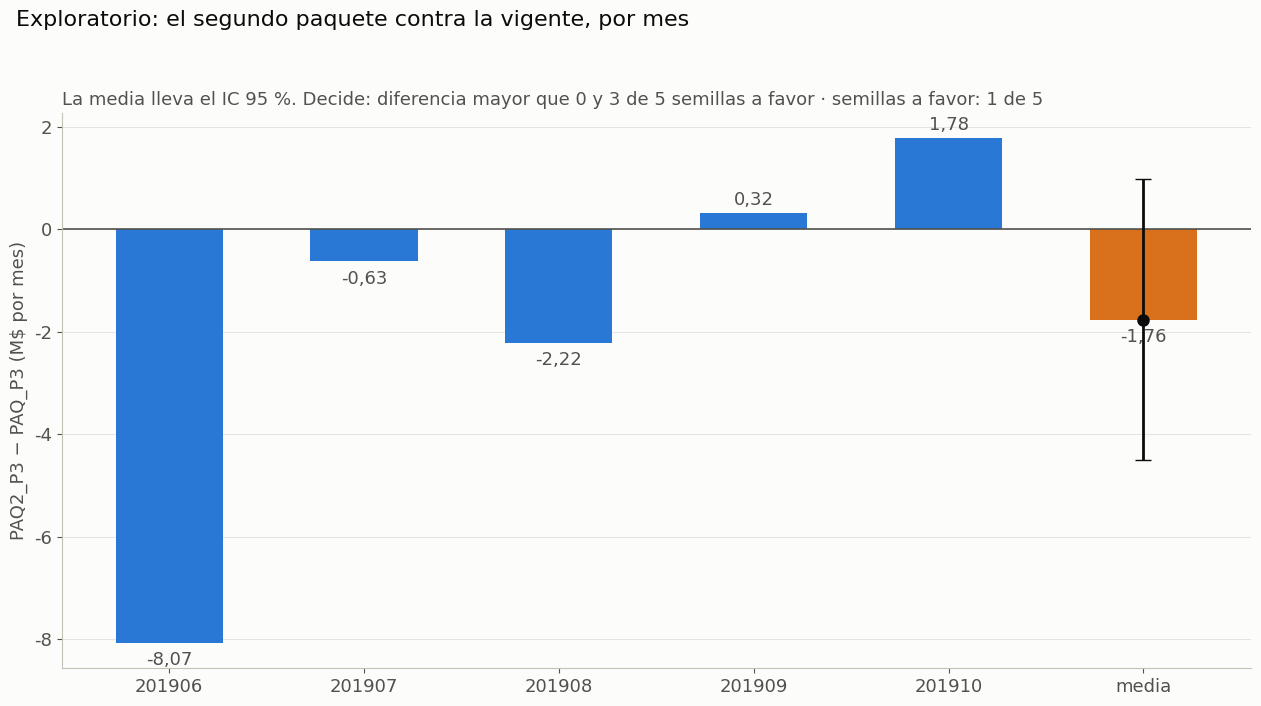

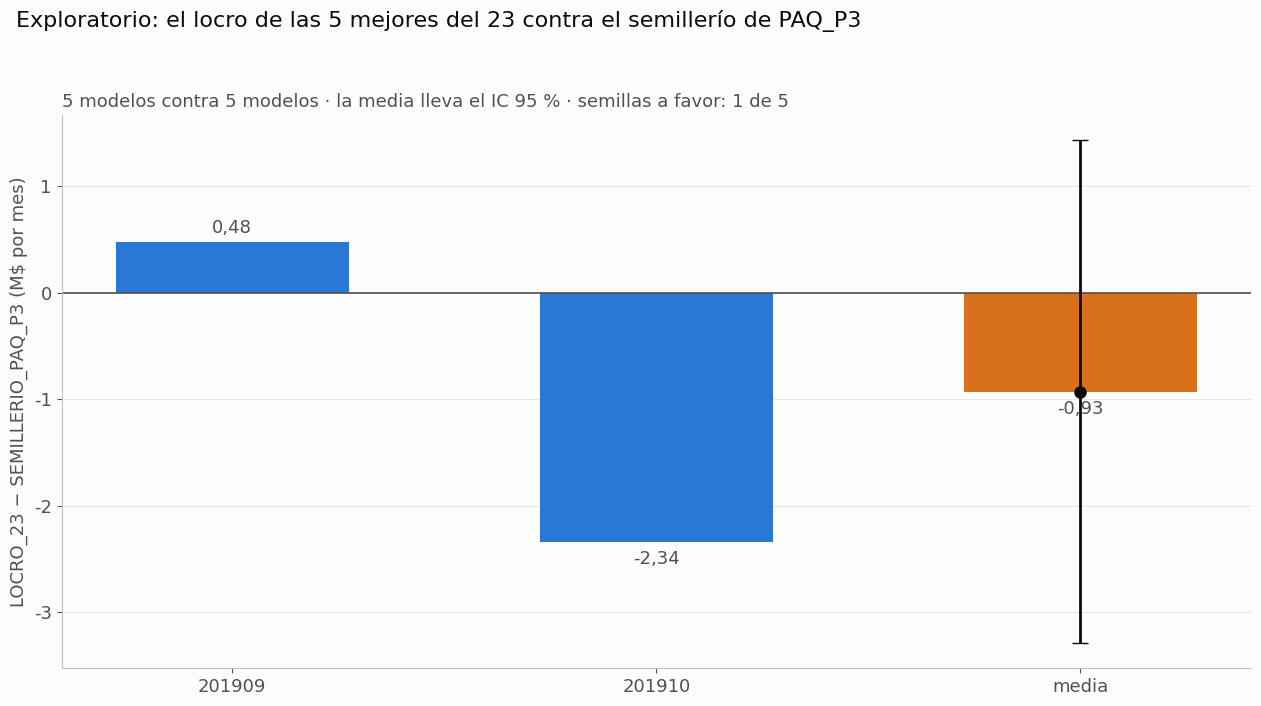

In [14]:
TINTA_2, GRILLA, AZUL, NARANJA = '#52514e', '#e1e0d9', '#2a78d6', '#d9711c'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 14})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


formato = FuncFormatter(lambda v, _: coma(v, 2).rstrip('0').rstrip(','))


def figura(c, contra, lista, titulo, subtitulo, archivo):
    r = comparacion[(comparacion['config'] == c) & (comparacion['contra'] == contra) & comparacion['decide']].iloc[0]
    x = [str(m) for m in lista] + ['media']
    y = [r[f'd_{m}'] for m in lista] + [r.d_M]
    fig, ax = plt.subplots(figsize=TAMANO)
    ax.axhline(0, color=TINTA_2, lw=1.2)
    ax.bar(x, y, color=[AZUL] * len(lista) + [NARANJA], width=0.55)
    ax.errorbar([x[-1]], [r.d_M], yerr=[[r.d_M - r.ic95_inf_M], [r.ic95_sup_M - r.d_M]], fmt='o', color='#0b0b0b', ms=8, capsize=6, lw=2)
    for xi, yi in zip(x, y):
        ax.annotate(coma(yi, 2), (xi, yi), textcoords='offset points', xytext=(0, 6 if yi >= 0 else -16), ha='center', color=TINTA_2)
    ax.yaxis.set_major_formatter(formato)
    ax.set_ylabel(f'{c} − {contra} (M$ por mes)')
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
    fig.suptitle(titulo, x=0.02, ha='left', fontsize=16)
    ax.set_title(subtitulo + f' · semillas a favor: {r.semillas_a_favor} de {N_SEMILLAS}', loc='left', color=TINTA_2, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURAS / archivo, dpi=DPI)
    plt.show()


figura(PAQUETE2, REFERENCIA, MESES_EVALUADOS, 'Exploratorio: el segundo paquete contra la vigente, por mes',
       'La media lleva el IC 95 %. Decide: diferencia mayor que 0 y 3 de 5 semillas a favor', '24_1_paquete.png')
figura(LOCRO, SEMILLERIO, MESES_LOCRO, 'Exploratorio: el locro de las 5 mejores del 23 contra el semillerío de PAQ_P3',
       '5 modelos contra 5 modelos · la media lleva el IC 95 %', '24_2_locro.png')

## 15. Lectura fijada antes de correr

Con `d` = la diferencia media en la banda, **regla de acumulación** (decisión del usuario del 2026-11-09):

| Resultado | Lectura |
|---|---|
| `d` mayor que 0 **y** al menos 3 de 5 semillas a favor | Suma |
| `d` de −1 M o menos | Resta |
| Cualquier otro caso | Empate |

- **`PAQ2_P3` − `PAQ_P3` (201906–10):** si suma, `PAQ2_P3` pasa a ser la vigente, y "todo menos uno" va en otro notebook.
- **Locro − semillerío (201909–10):** si suma, el locro de las 5 combinaciones pasa a ser la forma de usar la vigente.

El intervalo se informa siempre. **Control 9:** las salidas anteriores no cambiaron.

In [15]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 9
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()
lectura = lambda d, a_favor: 'Suma' if d > 0 and a_favor >= SEMILLAS_MINIMAS else ('Resta' if d <= -UMBRAL else 'Empate')
iteraciones = []
for r in comparacion.itertuples():
    resultado = lectura(r.d_M, r.semillas_a_favor) if r.decide else 'no decide'
    print(f'{r.config} − {r.contra}, {r.meses}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {resultado}' + (' · DECIDE' if r.decide else ''))
    if r.decide:
        iteraciones.append({'config': r.config, 'hipotesis': HIPOTESIS[r.config], 'contra': r.contra, 'meses': r.meses,
                            'd_M': round(r.d_M, 3), 'semillas_a_favor': r.semillas_a_favor, 'resultado': resultado, 'decide': True})
pd.DataFrame(iteraciones).to_csv(RESULTADOS / '24_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 120.0 min en total · memoria máxima 25.9 GB
Segundos por modelo: {'PAQ2_P3': 99.1, 'locro': 98.9}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

PAQ2_P3 − PAQ_P3, 201906-10: -1.76 M (-4.50 a 0.97) · error 1.40 M · semillas a favor 1 de 5 · Resta · DECIDE
LOCRO_23 − SEMILLERIO_PAQ_P3, 201909-10: -0.93 M (-3.29 a 1.44) · error 1.21 M · semillas a favor 1 de 5 · Empate · DECIDE
PAQ2_P3 − PAQ_P3, 201909-10: +1.05 M (-3.08 a 5.18) · error 2.11 M · semillas a favor 3 de 5 · no decide
